# Milestone 1: Dataset Setup and Exploration

This notebook explores the Football Image Dataset without changing its images or labels. It counts objects, draws example YOLO bounding boxes, examines soccer-ball box sizes, and checks the dataset for common integrity problems.

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import yaml
from PIL import Image, ImageDraw

# The notebook is stored in the dataset root.
DATASET_ROOT = Path.cwd()
if not (DATASET_ROOT / 'data.yaml').exists():
    raise FileNotFoundError('Run this notebook from the project root.')

with open(DATASET_ROOT / 'data.yaml', encoding='utf-8') as file:
    config = yaml.safe_load(file)

CLASS_NAMES = {int(key): value for key, value in config['names'].items()}
SPLITS = ('train', 'val')
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png'}
COLORS = {0: 'red', 1: 'lime', 2: 'cyan'}
CLASS_NAMES

{0: 'ball', 1: 'player', 2: 'referee'}

## 1. Find paired image and label files

In [2]:
images_by_split = {}
labels_by_split = {}
for split in SPLITS:
    images_by_split[split] = sorted(
        path for path in (DATASET_ROOT / 'images' / split).iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )
    labels_by_split[split] = sorted((DATASET_ROOT / 'labels' / split).glob('*.txt'))

total_images = sum(len(paths) for paths in images_by_split.values())
print(f'Total images: {total_images}')
for split in SPLITS:
    print(f'{split:>5}: {len(images_by_split[split])} images, {len(labels_by_split[split])} labels')

Total images: 612
train: 512 images, 512 labels
  val: 100 images, 100 labels


## 2. Validate labels and count annotations

In [3]:
counts_by_split = {split: Counter() for split in SPLITS}
issues = []
empty_labels = []
image_sizes = {}
ball_boxes = []  # split, image path, normalized width/height, pixel width/height

for split in SPLITS:
    image_stems = {path.stem: path for path in images_by_split[split]}
    label_stems = {path.stem: path for path in labels_by_split[split]}

    for stem in sorted(image_stems.keys() - label_stems.keys()):
        issues.append(f'Missing label: {split}/{stem}')
    for stem in sorted(label_stems.keys() - image_stems.keys()):
        issues.append(f'Missing image: {split}/{stem}')

    for stem in sorted(image_stems.keys() & label_stems.keys()):
        image_path = image_stems[stem]
        label_path = label_stems[stem]
        try:
            with Image.open(image_path) as image:
                image.verify()
            with Image.open(image_path) as image:
                image_width, image_height = image.size
            image_sizes[image_path] = (image_width, image_height)
        except Exception as error:
            issues.append(f'Unreadable image {image_path}: {error}')
            continue

        lines = [line.strip() for line in label_path.read_text().splitlines() if line.strip()]
        if not lines:
            empty_labels.append(label_path)

        for line_number, line in enumerate(lines, start=1):
            parts = line.split()
            location = f'{label_path}:{line_number}'
            if len(parts) != 5:
                issues.append(f'{location}: expected 5 values, found {len(parts)}')
                continue
            try:
                class_id = int(parts[0])
                x_center, y_center, width, height = map(float, parts[1:])
            except ValueError:
                issues.append(f'{location}: non-numeric value')
                continue

            if class_id not in CLASS_NAMES:
                issues.append(f'{location}: unknown class {class_id}')
                continue
            values = (x_center, y_center, width, height)
            if not all(np.isfinite(values)):
                issues.append(f'{location}: non-finite coordinate')
                continue
            if not all(0 <= value <= 1 for value in values):
                issues.append(f'{location}: coordinate outside [0, 1]')
                continue
            if width <= 0 or height <= 0:
                issues.append(f'{location}: width and height must be positive')
                continue
            # Count every otherwise valid annotation. Boundary-crossing boxes
            # are retained in the totals but also reported as geometry issues.
            counts_by_split[split][class_id] += 1
            if (x_center - width / 2 < 0 or x_center + width / 2 > 1 or
                    y_center - height / 2 < 0 or y_center + height / 2 > 1):
                issues.append(f'{location}: bounding box crosses image boundary')

            if class_id == 0:
                ball_boxes.append((split, image_path, width, height,
                                   width * image_width, height * image_height))

total_counts = sum(counts_by_split.values(), Counter())
for split in (*SPLITS, 'total'):
    counts = total_counts if split == 'total' else counts_by_split[split]
    summary = ', '.join(f'{CLASS_NAMES[i]}={counts[i]:,}' for i in sorted(CLASS_NAMES))
    print(f'{split:>5}: {summary}; all boxes={sum(counts.values()):,}')

train: ball=417, player=7,278, referee=634; all boxes=8,329
  val: ball=83, player=1,566, referee=158; all boxes=1,807
total: ball=500, player=8,844, referee=792; all boxes=10,136


## 3. Display five images containing soccer balls

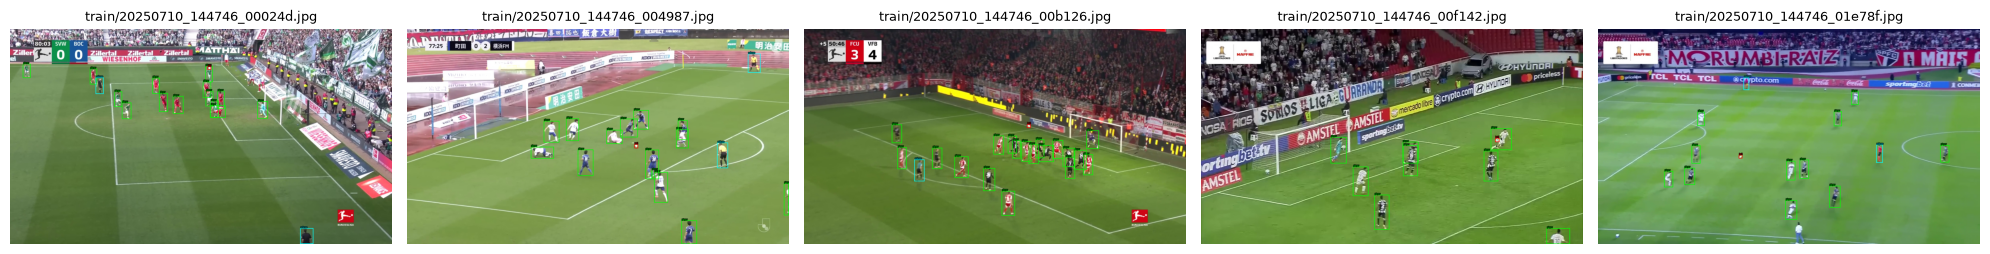

In [4]:
def load_yolo_boxes(label_path):
    boxes = []
    for line in label_path.read_text().splitlines():
        if line.strip():
            class_id, x, y, width, height = line.split()
            boxes.append((int(class_id), *map(float, (x, y, width, height))))
    return boxes

# Select the first five distinct images known to contain a ball.
example_paths = list(dict.fromkeys(row[1] for row in ball_boxes))[:5]
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for axis, image_path in zip(axes, example_paths):
    image = Image.open(image_path).convert('RGB')
    draw = ImageDraw.Draw(image)
    image_width, image_height = image.size
    split = image_path.parent.name
    label_path = DATASET_ROOT / 'labels' / split / f'{image_path.stem}.txt'
    for class_id, x, y, width, height in load_yolo_boxes(label_path):
        x1 = (x - width / 2) * image_width
        y1 = (y - height / 2) * image_height
        x2 = (x + width / 2) * image_width
        y2 = (y + height / 2) * image_height
        color = COLORS[class_id]
        draw.rectangle((x1, y1, x2, y2), outline=color, width=3)
        draw.text((x1 + 2, max(0, y1 - 12)), CLASS_NAMES[class_id], fill=color, stroke_width=2, stroke_fill='black')
    axis.imshow(image)
    axis.set_title(f'{split}/{image_path.name}', fontsize=9)
    axis.axis('off')
plt.tight_layout()
plt.show()

## 4. Soccer-ball bounding-box size distribution
Normalized area is the fraction of the full image covered by a bounding box. Pixel area gives the same measurement in pixels.

Ball boxes: 500
Normalized area — min: 0.00001750, median: 0.00015868, max: 0.00586189
Pixel area      — min: 36.3, median: 293.5, max: 12155.2


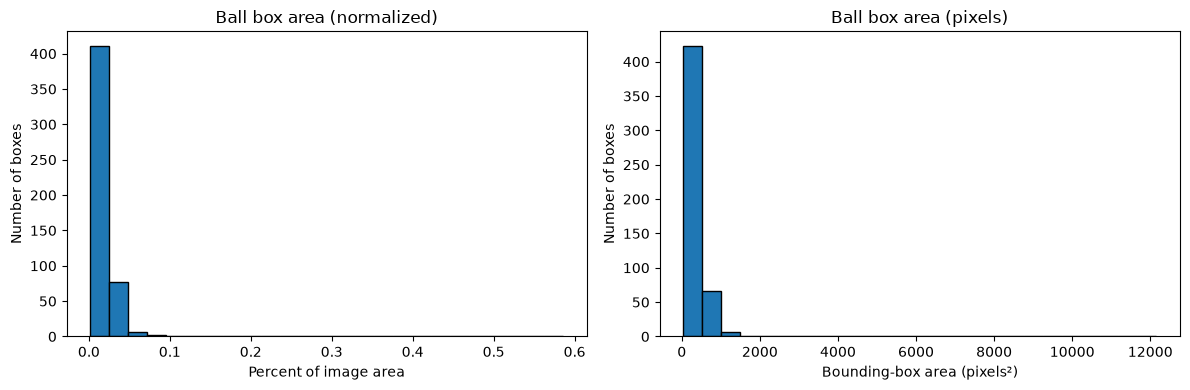

In [5]:
normalized_areas = np.array([row[2] * row[3] for row in ball_boxes])
pixel_areas = np.array([row[4] * row[5] for row in ball_boxes])

print(f'Ball boxes: {len(ball_boxes):,}')
print(f'Normalized area — min: {normalized_areas.min():.8f}, median: {np.median(normalized_areas):.8f}, max: {normalized_areas.max():.8f}')
print(f'Pixel area      — min: {pixel_areas.min():.1f}, median: {np.median(pixel_areas):.1f}, max: {pixel_areas.max():.1f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(normalized_areas * 100, bins=25, edgecolor='black')
axes[0].set(title='Ball box area (normalized)', xlabel='Percent of image area', ylabel='Number of boxes')
axes[1].hist(pixel_areas, bins=25, edgecolor='black')
axes[1].set(title='Ball box area (pixels)', xlabel='Bounding-box area (pixels²)', ylabel='Number of boxes')
plt.tight_layout()
plt.show()

## 5. Dataset issue report

In [6]:
dimension_counts = Counter(image_sizes.values())
print(f'Unreadable, missing, or invalid items: {len(issues)}')
for issue in issues[:20]:
    print(' -', issue)
if len(issues) > 20:
    print(f' ... and {len(issues) - 20} more')

print(f'Empty label files (background images): {len(empty_labels)}')
for path in empty_labels:
    print(' -', path.relative_to(DATASET_ROOT))
print('Image dimensions:', dict(dimension_counts))

Unreadable, missing, or invalid items: 19
 - C:\Users\javie\OneDrive\Documents\data4620\Football-Image-Dataset-main\labels\train\20250710_144746_058cde.txt:9: bounding box crosses image boundary
 - C:\Users\javie\OneDrive\Documents\data4620\Football-Image-Dataset-main\labels\train\20250710_144746_0c5785.txt:3: bounding box crosses image boundary
 - C:\Users\javie\OneDrive\Documents\data4620\Football-Image-Dataset-main\labels\train\20250710_144746_0f4681.txt:11: bounding box crosses image boundary
 - C:\Users\javie\OneDrive\Documents\data4620\Football-Image-Dataset-main\labels\train\20250710_144746_16e0f7.txt:16: bounding box crosses image boundary
 - C:\Users\javie\OneDrive\Documents\data4620\Football-Image-Dataset-main\labels\train\20250710_144746_173c2e.txt:11: bounding box crosses image boundary
 - C:\Users\javie\OneDrive\Documents\data4620\Football-Image-Dataset-main\labels\train\20250710_144746_19dab9.txt:9: bounding box crosses image boundary
 - C:\Users\javie\OneDrive\Documents\